# Imports

##### standard python libraries

In [1]:
import os
from sqlalchemy import create_engine
import polars as pl
import numpy as np
import re
import seaborn as sns
import matplotlib.pyplot as plt
import cartopy

In [2]:
import warnings
warnings.filterwarnings('ignore')

##### Custom Libraries

In [3]:
import psql_utilities as psql_utl
import Library_sampling as sampling

### Set Paths

In [4]:
### path to configuration file of database
path_conf_file = './../../config/database.ini'
###
path_tmp_data = './data/'

### Database Connection

In [5]:
db_config = psql_utl.load_config(path_conf_file)
#db_conn = psql_utl.connect(db_config)
### connect to the database - sqlalchemy
engine = create_engine(db_config['db_uri'])

## Stratified Importance Sampling (SIS)

In this notebook we perform the so called Stratified Importance Sampling SIS proposed in

> Abbate, A., Davies, G., Lorito, S., Kalligeris, N., Romano, F., Tonini, R., and Volpe, M. (2025), 
> *Importance sampling of seismic tsunami sources with nearfield emphasis for inundation PTHA: benchmarking with complete ensembles*, 
> *Geophys. J. Int.*, 241, 155–169,
> https://doi.org/10.1093/gji/ggaf034

SIS is a procedure to select a smaller subset of **representative scenarios** that approximate the same hazard curves coming from all scenarios. 
The idea is the following
   
   1. Assign a weight to each scenario: the weight measures the “importance” of a scenario. We define the weight as:
          $
          w_s = \lambda_s \cdot H_s^{max} \cdot \frac{1}{T_s^{arr}}
          $
      This means that we give more importance to scenarios that:
        - happen, on average, more often (high rate $\lambda_s$),
        - produce larger waves ($H_s^{max}$),
        - arrive earlier -> **focus on near field** ($\frac{1}{T_s^{arr}}$).

   2. Scenarios are divided based on their magnitude.

   3. We select a fixed number of scenarios in each bin: scenarios with higher weight are more likely to be selected.


In order to perform the analysis the user can select for a given value of *manning coefficient*:

  1. the value of *manning coefficient*
  2. the target site: Catania or Siracusa

Then we select from metadata the associated simulation run parameters, see *'./query_sampling_v1.sql'*. 

In order to obtain a nice plots we also extract the triangles of mesh associated to the PS sceanarios, see *'./query_sampling_v1.sql'*.

### setup

##### read query from file

In [6]:
query_params = open("./query_sampling_v1.sql", "r")
query_params = query_params.read()
#
query_mesh = open("./query_meshes.sql", "r")
query_mesh = query_mesh.read()

##### set input variables

In [7]:
# manning coefficient
manning_coef = 0.03
# location of interest (CT,SR)
site = "CT"

### query result

##### extract SR parameters

In [8]:
dict_params = {'manning_coef': manning_coef,
               'site_loc': site}

In [9]:
query_params_completed = query_params % dict_params
df_scen_params = pl.read_database_uri(query_params_completed,engine='connectorx',uri=db_config['db_uri'],partition_num=6)
df_scen_params = df_scen_params.to_pandas()
df_scen_params

,id_scen,seismicity_type,avg_rate,avg_rate_norm,rates,magnitude,lon,lat,max_ts,arrival_time_min
0,E01267N3753E01646N3535-BS-M754_E01527N3715_D09...,BS,7.418632e-09,7.672063e-07,"[2.25764147683233e-08, 6.35417437974e-09, 3.88...",7.54,15.2708,37.1526,1.016812,11.011229
1,E01889N4173E02097N3847-BS-M732_E02025N3917_D01...,BS,8.065293e-06,9.263010e-04,"[1.2594429409671e-05, 4.902423515454e-06, 1.19...",7.32,20.2566,39.1761,0.119521,56.004724
2,E01267N3753E01646N3535-BS-M809_E01592N3602_D01...,BS,2.305902e-10,6.933078e-08,"[0.0, 3.3562268429424e-11, 0.0, 1.9735273248e-...",8.09,15.9273,36.0284,0.964149,13.508868
3,E01267N3753E01646N3535-BS-M774_E01551N3692_D01...,BS,1.228376e-08,2.241234e-06,"[1.4176281614076e-07, 9.006774891136e-09, 4.87...",7.74,15.5157,36.9278,0.672238,9.005912
4,E01267N3753E01646N3535-BS-M809_E01575N3670_D01...,BS,5.664580e-10,1.703150e-07,"[0.0, 9.023596482252e-10, 0.0, 1.940366018e-12...",8.09,15.7595,36.7029,2.366291,15.009853
...,...,...,...,...,...,...,...,...,...,...
53545,E01964N3926E02184N3685-PS-Mur_PYes_Hom-M824_E0...,PS,3.867297e-06,1.160960e-03,"[2.40871990154459e-05, 0.0, 3.07553998154995e-...",8.24,20.5700,37.2400,0.302847,39.002055
53546,E02020N3739E02658N3366-PS-Str_PYes_Hom-M861_E0...,PS,3.121311e-08,7.036218e-05,"[5.26777372452118e-08, 0.0, 1.86045509660275e-...",8.61,24.2500,34.4000,0.571178,74.507576
53547,E02113N3823E02873N3483-PS-Mur_PNo_Var-M871_E02...,PS,1.681463e-07,1.430761e-03,"[0.0, 1.32787951187979e-06, 0.0, 0.0, 0.0, 2.2...",8.71,23.5800,35.6200,0.353521,78.506413
53548,E02020N3739E02658N3366-PS-Str_PYes_Hom-M861_E0...,PS,1.542110e-08,3.476302e-05,"[4.11034738505168e-08, 0.0, 0.0, 0.0, 4.119973...",8.61,21.0600,35.8000,1.616963,59.510132


##### extract PS mesh faults

In [10]:
pattern = '\(\(([^(].*?)\)\)'
#
query_mesh_completed = query_mesh % dict_params
df_mesh = pl.read_database_uri(query_mesh_completed,engine='connectorx',uri=db_config['db_uri'],partition_num=6)
df_mesh

fk_sr_id,seismicity_type,mesh_fault
str,str,str
"""sr_301671""","""PS""","""MULTIPOLYGON Z (((22.5357 34.1…"
"""sr_301651""","""PS""","""MULTIPOLYGON Z (((16.0239 37.5…"
"""sr_301672""","""PS""","""MULTIPOLYGON Z (((21.1217 35.2…"
"""sr_301652""","""PS""","""MULTIPOLYGON Z (((24.6925 33.5…"
"""sr_301653""","""PS""","""MULTIPOLYGON Z (((17.0465 36.8…"
…,…,…
"""sr_310852""","""PS""","""MULTIPOLYGON Z (((20.9507 35.9…"
"""sr_310853""","""PS""","""MULTIPOLYGON Z (((20.1856 37.7…"
"""sr_310854""","""PS""","""MULTIPOLYGON Z (((25.3084 33.4…"


### Important Sampling

##### Define the weight of the scenarios

⚠️ **Note**  
You can set your own proposal.
For instance:

1. Simple stratified sampling (Davies et al. 2022):
   proposal_offshore = mean_rates
2. Stratified importance sampling (Davies et al. 2022):
   proposal_offshore = mean_rates * mwa_off
3. Stratified importance sampling (Abbate et al. 2025):
   proposal_offshore = mean_rates * mwa_off * time
   In the last configuration, a $tmin$ value should be selected to emphasize near-field effect.
   You can choose it, for instance, looking at the plot above.

In [11]:
tmin = 1
inverse_time = 1 / df_scen_params['arrival_time_min'].clip(lower=tmin)

# 2. Vectorized multiplication across all columns at once
df_scen_params['proposal'] = df_scen_params['avg_rate'] * df_scen_params['max_ts'] * inverse_time
df_scen_params

,id_scen,seismicity_type,avg_rate,avg_rate_norm,rates,magnitude,lon,lat,max_ts,arrival_time_min,proposal
0,E01267N3753E01646N3535-BS-M754_E01527N3715_D09...,BS,7.418632e-09,7.672063e-07,"[2.25764147683233e-08, 6.35417437974e-09, 3.88...",7.54,15.2708,37.1526,1.016812,11.011229,6.850600e-10
1,E01889N4173E02097N3847-BS-M732_E02025N3917_D01...,BS,8.065293e-06,9.263010e-04,"[1.2594429409671e-05, 4.902423515454e-06, 1.19...",7.32,20.2566,39.1761,0.119521,56.004724,1.721230e-08
2,E01267N3753E01646N3535-BS-M809_E01592N3602_D01...,BS,2.305902e-10,6.933078e-08,"[0.0, 3.3562268429424e-11, 0.0, 1.9735273248e-...",8.09,15.9273,36.0284,0.964149,13.508868,1.645757e-11
3,E01267N3753E01646N3535-BS-M774_E01551N3692_D01...,BS,1.228376e-08,2.241234e-06,"[1.4176281614076e-07, 9.006774891136e-09, 4.87...",7.74,15.5157,36.9278,0.672238,9.005912,9.169100e-10
4,E01267N3753E01646N3535-BS-M809_E01575N3670_D01...,BS,5.664580e-10,1.703150e-07,"[0.0, 9.023596482252e-10, 0.0, 1.940366018e-12...",8.09,15.7595,36.7029,2.366291,15.009853,8.930163e-11
...,...,...,...,...,...,...,...,...,...,...,...
53545,E01964N3926E02184N3685-PS-Mur_PYes_Hom-M824_E0...,PS,3.867297e-06,1.160960e-03,"[2.40871990154459e-05, 0.0, 3.07553998154995e-...",8.24,20.5700,37.2400,0.302847,39.002055,3.002915e-08
53546,E02020N3739E02658N3366-PS-Str_PYes_Hom-M861_E0...,PS,3.121311e-08,7.036218e-05,"[5.26777372452118e-08, 0.0, 1.86045509660275e-...",8.61,24.2500,34.4000,0.571178,74.507576,2.392809e-10
53547,E02113N3823E02873N3483-PS-Mur_PNo_Var-M871_E02...,PS,1.681463e-07,1.430761e-03,"[0.0, 1.32787951187979e-06, 0.0, 0.0, 0.0, 2.2...",8.71,23.5800,35.6200,0.353521,78.506413,7.571770e-10
53548,E02020N3739E02658N3366-PS-Str_PYes_Hom-M861_E0...,PS,1.542110e-08,3.476302e-05,"[4.11034738505168e-08, 0.0, 0.0, 0.0, 4.119973...",8.61,21.0600,35.8000,1.616963,59.510132,4.190100e-10


##### Group scenarios by bins of magnitude

create dataframe with bins

In [12]:
df_scen_bins = df_scen_params.groupby("magnitude").agg(counts=("id_scen", "count")).reset_index()
df_scen_bins

,magnitude,counts
0,6.00,4
1,6.50,293
2,6.80,1225
3,7.07,2800
4,7.32,4080
5,7.54,5800
6,7.74,5845
7,7.92,7056
8,8.09,6040
9,8.24,2062


Plots within bins

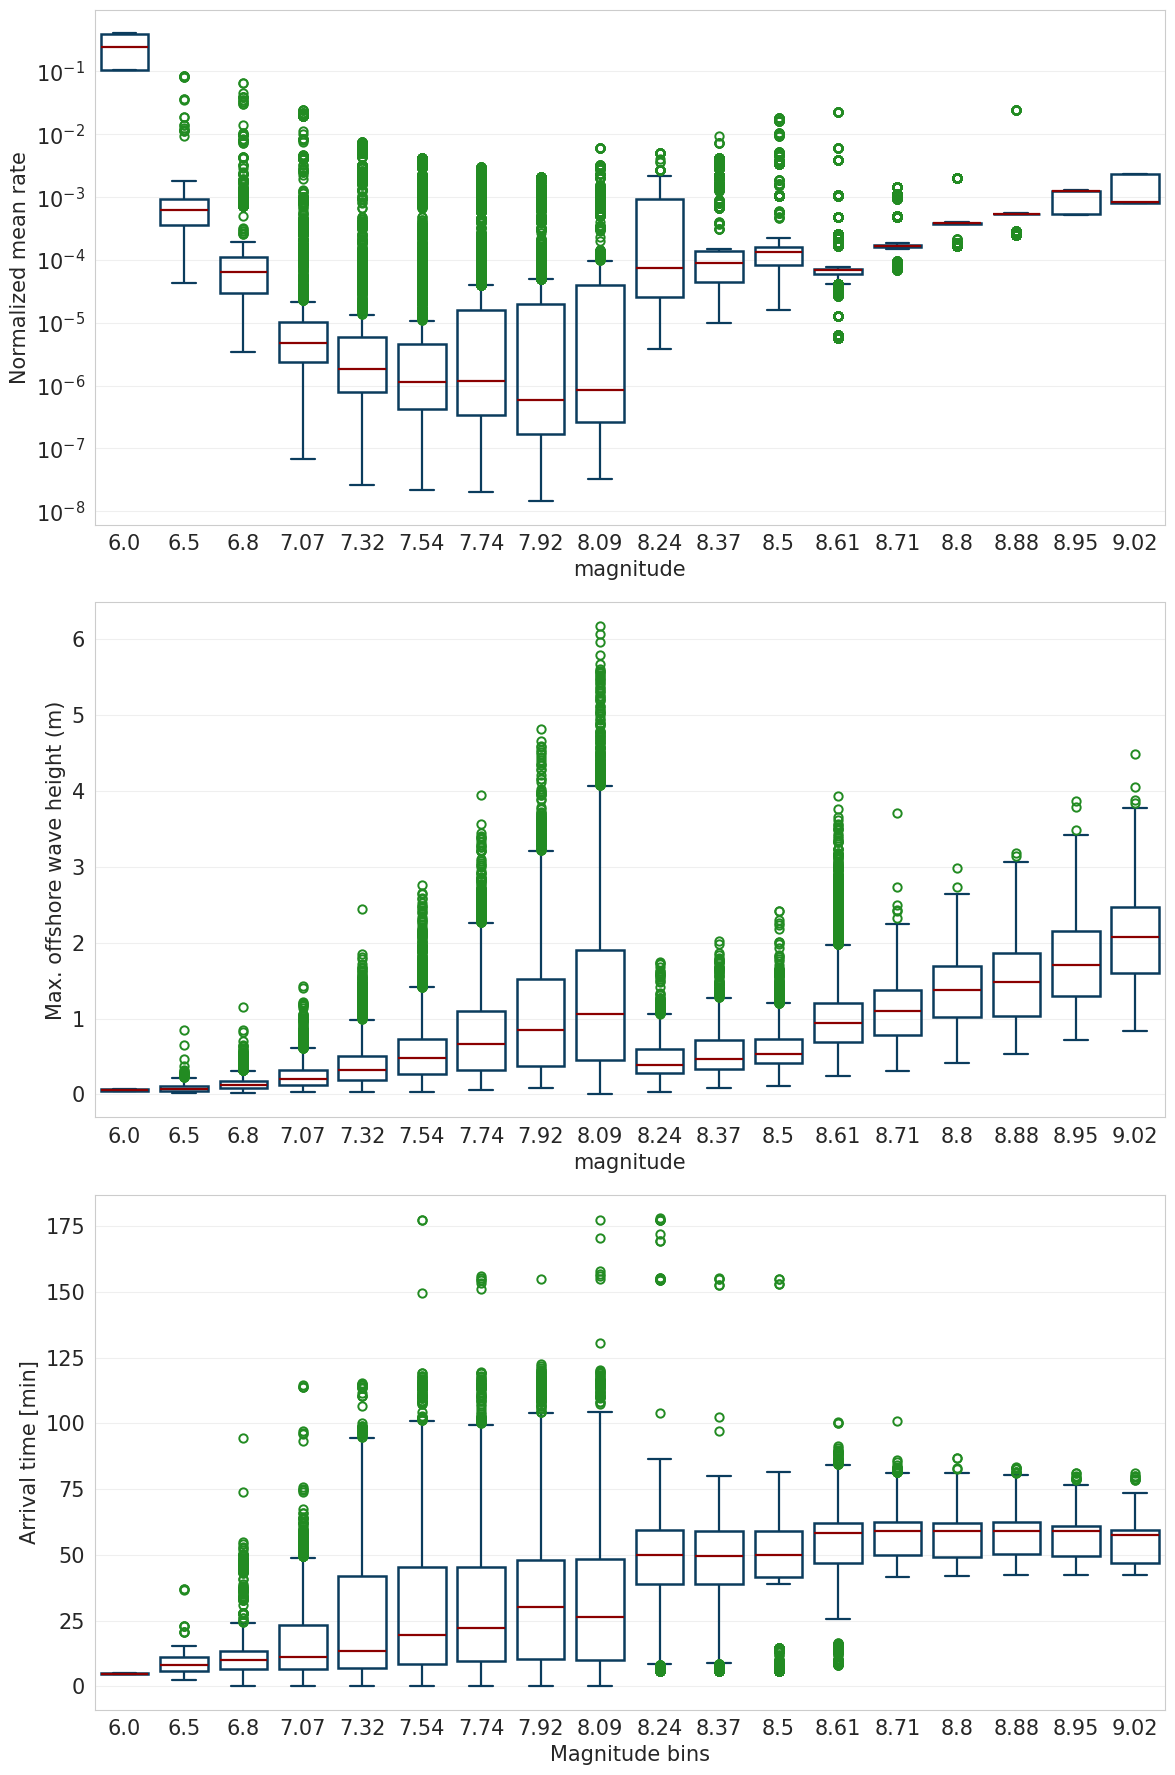

In [13]:
# =========================
# To visualize what happens within each bin
# =========================
FONT_SIZE = 15
mw_bins = df_scen_bins['magnitude'].to_numpy()

plt.rcParams.update({
    "font.size": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "legend.fontsize": FONT_SIZE
})

sns.set_style("whitegrid")

dark_blue = "#0b3c5d"
dark_red = "#8b0000"
green = "#228b22"

boxprops     = dict(edgecolor = dark_blue, linewidth = 1.8, facecolor = 'none')
whiskerprops = dict(color     = dark_blue, linewidth = 1.6)
capprops     = dict(color     = dark_blue, linewidth = 1.6)
medianprops  = dict(color     = dark_red,  linewidth = 1.6)  
#meanprops    = dict(marker='o',
#                    markerfacecolor=dark_red,
#                    markeredgecolor=dark_red,
#                    markersize=7)
flierprops   = dict(marker          = 'o',
                    markerfacecolor = 'none',
                    markeredgecolor = green,
                    markeredgewidth = 1.4,
                    markersize      = 6,
                    linestyle       = 'none')
fig, axes = plt.subplots(3, 1, figsize = (12, 18))#, sharex = True)

"""
1) Rates
"""
sns.boxplot(
    data         = df_scen_params,
    x            = "magnitude",
    y            = "avg_rate_norm",
    order        = mw_bins,
    ax           = axes[0],
    #showmeans=True,
    boxprops     = boxprops,
    whiskerprops = whiskerprops,
    capprops     = capprops,
    medianprops  = medianprops,
    #meanprops    = meanprops,
    flierprops   = flierprops
)
axes[0].set_yscale("log")
#axes[0].set_xlabel("Magnitude bins")
axes[0].set_ylabel("Normalized mean rate")
#axes[0].set_title("Annual rates")


"""
2) Max. offshore height 
"""
sns.boxplot(
    data         = df_scen_params,
    x            = "magnitude",
    y            = "max_ts",
    order        = mw_bins,
    ax           = axes[1],
    #showmeans=True,
    boxprops     = boxprops,
    whiskerprops = whiskerprops,
    capprops     = capprops,
    medianprops  = medianprops,
    #meanprops=meanprops,
    flierprops   = flierprops
)
#axes[1].set_xlabel("Magnitude bins")
axes[1].set_ylabel("Max. offshore wave height (m)")
#axes[1].set_title("Offshore maximum height")
"""
3) Arrival time
"""
sns.boxplot(
    data         = df_scen_params,
    x            = "magnitude",
    y            = "arrival_time_min",
    order        = mw_bins,
    ax           = axes[2],
    #showmeans=True,
    boxprops     = boxprops,
    whiskerprops = whiskerprops,
    capprops     = capprops,
    medianprops  = medianprops,
    #meanprops=meanprops,
   flierprops    = flierprops
)
axes[2].set_xlabel("Magnitude bins")
axes[2].set_ylabel("Arrival time [min]")
#axes[2].set_title("Arrival time")

# Migliorie estetiche
for ax in axes:
    ax.tick_params(axis = 'x', rotation = 0)
    ax.grid(True, axis  = 'y', alpha    = 0.3)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

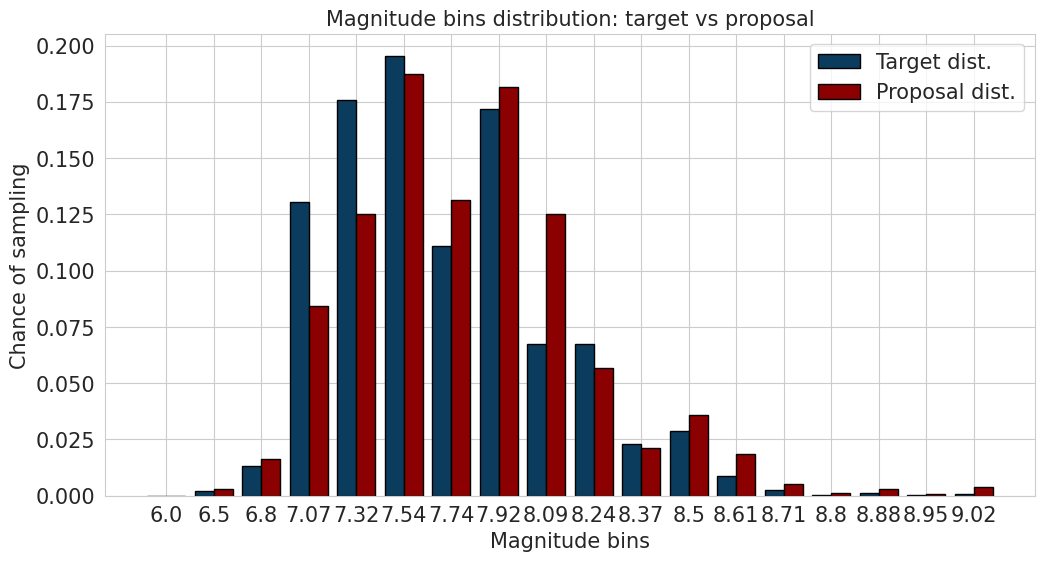

In [14]:
#target = mean_rates

proposal_bin = df_scen_params.groupby("magnitude")["proposal"].sum()
target_bin   = df_scen_params.groupby("magnitude")["avg_rate"].sum()

# Global normalization
proposal_bin = proposal_bin / proposal_bin.sum()
target_bin   = target_bin / target_bin.sum()


x = np.arange(len(proposal_bin))

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(x - 0.2, target_bin.values, width=0.4, color=dark_blue, edgecolor='black', label="Target dist.")
ax.bar(x + 0.2, proposal_bin.values, width=0.4, color=dark_red, edgecolor='black', label="Proposal dist.")

ax.set_xticks(x)
ax.set_xticklabels(proposal_bin.index)

ax.set_xlabel("Magnitude bins")
ax.set_ylabel("Chance of sampling")
ax.set_title("Magnitude bins distribution: target vs proposal")
ax.legend()

plt.show()

##### Scenarios Sampling

⚠️ **Note**  
You can set your own num_samples. In principle, the greater, the better. 
A balance between accuracy and efficiency is required.

In [15]:
num_samples = 3500

In [16]:
mw = df_scen_params['magnitude'].to_numpy()
mw_bins = df_scen_bins['magnitude'].to_numpy()
mw_counts = df_scen_bins['counts'].to_numpy()
mean_rates = df_scen_params['avg_rate'].to_numpy()
proposal_offshore = df_scen_params['proposal'].to_numpy()
mwa_off = df_scen_params['max_ts'].to_numpy()
#
ix_sis, n_sis = sampling.optimized_mc_sis(mw, 
                                 mw_bins,
                                 mw_counts,
                                 #thresholds,
                                 mean_rates,
                                 proposal_offshore,
                                 mwa_off,
                                 num_samples)
#df_scen_bins['counts_sis'] = n_sis

##### select results of sampled scenarios

In [18]:
df_samp = df_scen_params.iloc[ix_sis]
df_samp

,id_scen,seismicity_type,avg_rate,avg_rate_norm,rates,magnitude,lon,lat,max_ts,arrival_time_min,proposal
1475,E01267N3753E01646N3535-BS-M600_E01530N3737_D01...,BS,2.019343e-07,0.386472,"[1.59834341311793e-07, 4.80090981959462e-07, 1...",6.00,15.3075,37.3774,0.076447,4.502957,3.428243e-09
1475,E01267N3753E01646N3535-BS-M600_E01530N3737_D01...,BS,2.019343e-07,0.386472,"[1.59834341311793e-07, 4.80090981959462e-07, 1...",6.00,15.3075,37.3774,0.076447,4.502957,3.428243e-09
2583,E01267N3753E01646N3535-BS-M600_E01530N3737_D01...,BS,2.110240e-07,0.403869,"[1.31883380714287e-07, 9.33228233435123e-08, 1...",6.00,15.3075,37.3774,0.072403,4.502957,3.393071e-09
2583,E01267N3753E01646N3535-BS-M600_E01530N3737_D01...,BS,2.110240e-07,0.403869,"[1.31883380714287e-07, 9.33228233435123e-08, 1...",6.00,15.3075,37.3774,0.072403,4.502957,3.393071e-09
1475,E01267N3753E01646N3535-BS-M600_E01530N3737_D01...,BS,2.019343e-07,0.386472,"[1.59834341311793e-07, 4.80090981959462e-07, 1...",6.00,15.3075,37.3774,0.076447,4.502957,3.428243e-09
...,...,...,...,...,...,...,...,...,...,...,...
36958,E02020N3739E02658N3366-PS-Mur_PYes_Hom-M902_E0...,PS,9.371841e-08,0.002301,"[5.87966699966112e-08, 0.0, 4.33648405151992e-...",9.02,23.4400,34.7800,2.742244,48.510258,5.297822e-09
52613,E02020N3739E02658N3366-PS-Mur_PYes_Hom-M902_E0...,PS,9.500525e-08,0.002332,"[6.1304107304046e-08, 0.0, 4.39523003677388e-0...",9.02,22.7900,35.1400,1.698744,45.004513,3.586076e-09
40303,E02020N3739E02658N3366-PS-Mur_PYes_Var-M902_E0...,PS,9.500525e-08,0.002332,"[6.1304107304046e-08, 0.0, 4.39523003677388e-0...",9.02,22.7900,35.1400,1.941520,58.506217,3.152736e-09
30679,E02020N3739E02658N3366-PS-Str_PYes_Hom-M902_E0...,PS,3.334134e-08,0.000818,"[6.08895596894988e-08, 0.0, 0.0, 0.0, 6.102915...",9.02,22.4500,35.1500,2.372841,47.502307,1.665471e-09


### Plots Results

##### Plot hazard curves at the selected offshore site

In [19]:
"""
Update rates:
original scenario rates must be rescaled according
to their weight to preserve the features of the hazard.
"""
#df_samp = df_scen_params.iloc[ix_sis]
mw_sis         = df_samp['magnitude'].to_numpy()
lon_sis        = df_samp['lon'].to_numpy()
lat_sis        = df_samp['lat'].to_numpy()
ids_sis        = df_samp['id_scen'].to_numpy()
rates_sis      = np.array(df_samp['rates'].to_list())
mean_rates_sis = df_samp['avg_rate'].to_numpy()
mwa_off_sis    = df_samp['max_ts'].to_numpy()
proposal_sis   = df_samp['proposal'].to_numpy()
#
rates = np.array(df_scen_params['rates'].to_list())
new_rates_sis  = sampling.update_rates_sis(mw_bins, mw, mw_sis, rates, rates_sis, proposal_offshore, proposal_sis, n_sis)


In [20]:
thresholds = np.array([1.000e-02, 5.000e-02, 1.000e-01, 2.000e-01,
       3.000e-01, 5.000e-01, 8.000e-01, 1.000e+00,
       1.500e+00, 2.000e+00, 2.500e+00, 3.000e+00,
       3.600e+00, 4.320e+00, 5.180e+00, 6.220e+00,
       7.460e+00, 8.950e+00, 1.074e+01, 1.289e+01,
       1.547e+01, 1.856e+01, 2.227e+01])

# Mean exceedance rate and percentiles from full ensemble
lambda_true = sampling.exceedance_curve(thresholds, mwa_off, rates)
lambda_true_mean = lambda_true.mean(axis=1)

p2  = np.percentile(lambda_true, 2, axis=1)
p16 = np.percentile(lambda_true, 16, axis=1)
p84 = np.percentile(lambda_true, 84, axis=1)
p98 = np.percentile(lambda_true, 98, axis=1)

# Mean exceedance rate and percentiles from sampled ensemble
lambda_sis = sampling.exceedance_curve(thresholds, mwa_off_sis, new_rates_sis)
lambda_sis_mean = lambda_sis.mean(axis=1)

p2_sis  = np.percentile(lambda_sis, 2, axis=1)
p16_sis = np.percentile(lambda_sis, 16, axis=1)
p84_sis = np.percentile(lambda_sis, 84, axis=1)
p98_sis = np.percentile(lambda_sis, 98, axis=1)

# Analytical Monte Carlo SIS error (that can be computed only at offshore sites) 
# and 95% confidence interval
var_an = sampling.analytical_variance_importance(mw, mw_bins,mean_rates, mwa_off, proposal_offshore, thresholds, n_sis) 
an_sis_up = lambda_true_mean + 1.96 * var_an
an_sis_dw = lambda_true_mean - 1.96 * var_an

Text(0.5, 1.0, 'Hazard Curve at Offshore point CT')

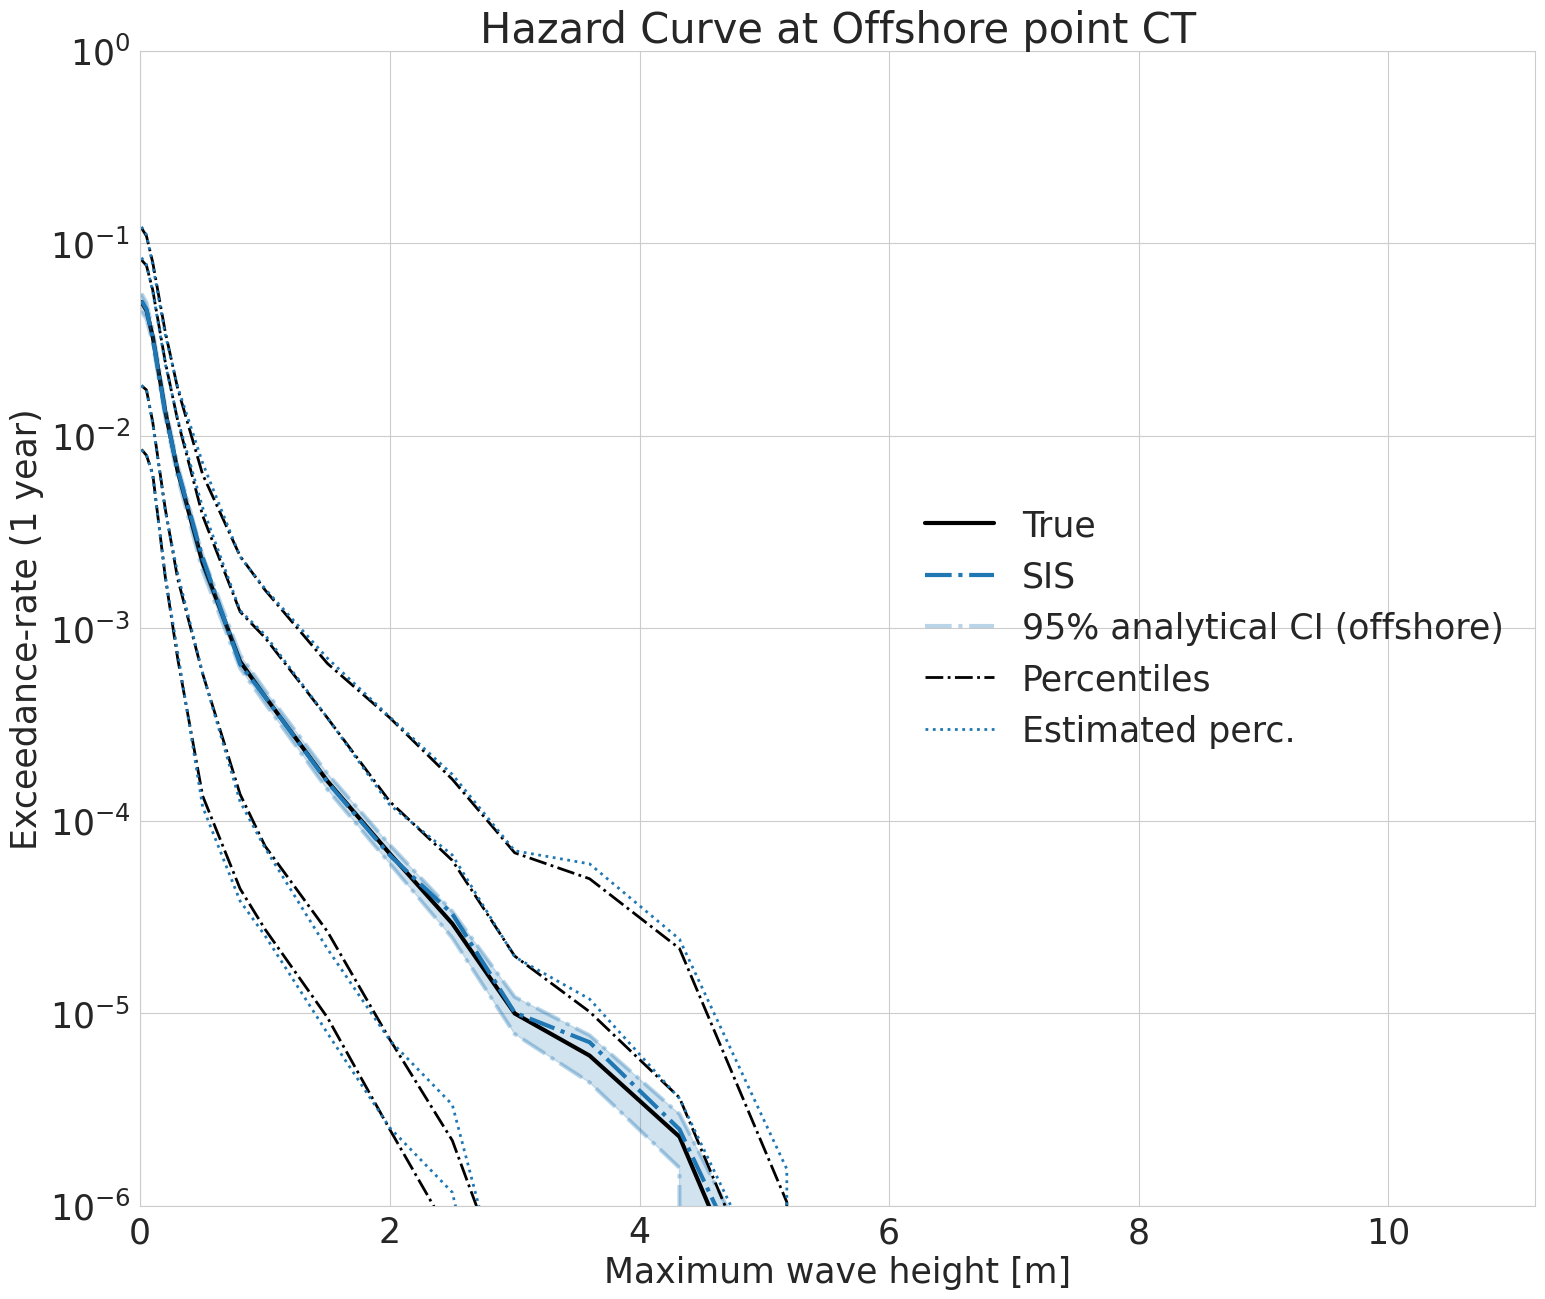

In [21]:
sis_poi = site
#
fig, ax = plt.subplots(figsize=(18,15))
ax.plot(thresholds, lambda_true_mean, color='black', linewidth=3, label='True')
ax.plot(thresholds, lambda_sis_mean, color='tab:blue', linestyle='-.', linewidth=3, label='SIS')

ax.fill_between(thresholds, an_sis_dw, an_sis_up, color='tab:blue', alpha=0.2)
ax.plot(thresholds, an_sis_up, color='tab:blue', linewidth=3, linestyle='-.', alpha=0.3, label='95% analytical CI (offshore)')
ax.plot(thresholds, an_sis_dw, color='tab:blue', linewidth=3, linestyle='-.', alpha=0.3, label='')

ax.plot(thresholds, p2, color='black', linewidth=2, linestyle='-.',  label='')
ax.plot(thresholds, p16, color='black', linewidth=2, linestyle='-.',  label='Percentiles')
ax.plot(thresholds, p84, color='black', linewidth=2, linestyle='-.',  label='')
ax.plot(thresholds, p98, color='black', linewidth=2, linestyle='-.',  label='')

ax.plot(thresholds, p2_sis, color='tab:blue', linewidth=2, linestyle=':',  label='Estimated perc.')
ax.plot(thresholds, p16_sis, color='tab:blue', linewidth=2, linestyle=':',  label='')
ax.plot(thresholds, p84_sis, color='tab:blue', linewidth=2, linestyle=':',  label='')
ax.plot(thresholds, p98_sis, color='tab:blue', linewidth=2, linestyle=':',  label='')

#ax.set_xscale('log')
ax.set_yscale('log')

ax.set_ylim([1e-6, 1])
ax.set_xlim([0, mwa_off.max()+5])

ax.set_xlabel("Maximum wave height [m]", fontsize=25)
ax.set_ylabel("Exceedance-rate (1 year)", fontsize=25)

plt.legend(fontsize=25, frameon=False, loc="center right")
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.title("Hazard Curve at Offshore point {}".format(sis_poi), fontsize=30)

##### Plot sampled scenarios on map

In [22]:
# BS seismicity
df_bs = df_scen_params[df_scen_params['seismicity_type']=='BS']
df_samp_bs = df_samp[df_samp['seismicity_type']=='BS']
ix_bs = np.array(df_samp_bs.index)
lon_bs_sis = df_samp_bs['lon'].to_numpy()
lat_bs_sis = df_samp_bs['lat'].to_numpy()
lon_bs = df_bs['lon'].to_numpy()
lat_bs = df_bs['lat'].to_numpy()
#
# PS seismicity
df_ps = df_scen_params[df_scen_params['seismicity_type']=='PS']
df_samp_ps = df_samp[df_samp['seismicity_type']=='PS']
ix_ps = np.array(df_samp_ps.index)
lon_ps_sis = df_samp_ps['lon'].to_numpy()
lat_ps_sis = df_samp_ps['lat'].to_numpy()
lon_ps = df_ps['lon'].to_numpy()
lat_ps = df_ps['lat'].to_numpy()
#
# mesh faults (we compute them only the first time)
cache_mesh_file = f"{path_tmp_data}/mesh_triangles.txt"
if os.path.exists(cache_mesh_file):
    print("Load mesh triangles from file")
    mesh_med = np.loadtxt(cache_mesh_file)
else:
    ### compute mesh triangles
    print("Extracting mesh triangles...")
    df_mesh_triangles = df_mesh.with_columns(pl.col('mesh_fault').map_elements(lambda x: re.findall(pattern, x),return_dtype=pl.List(pl.String)))\
                    .explode(pl.col('mesh_fault'))\
                    .with_columns(pl.col('mesh_fault').map_elements(lambda x: " ".join([f"{item.split(' ')[0]} {item.split(' ')[1]}" for item in x.split(',')]),pl.String).alias('mesh_triangle'))\
                    .select('mesh_triangle').unique()\
                    .with_columns(pl.col("mesh_triangle").str.split(" ").cast(pl.List(pl.Float64)))
    mesh_med = np.array(df_mesh_triangles["mesh_triangle"].to_list())
    ### save them
    print("Save mesh triangles in a file")
    os.makedirs(path_tmp_data, exist_ok=True)
    np.savetxt(cache_mesh_file, mesh_med, fmt='%g')

Load mesh triangles from file


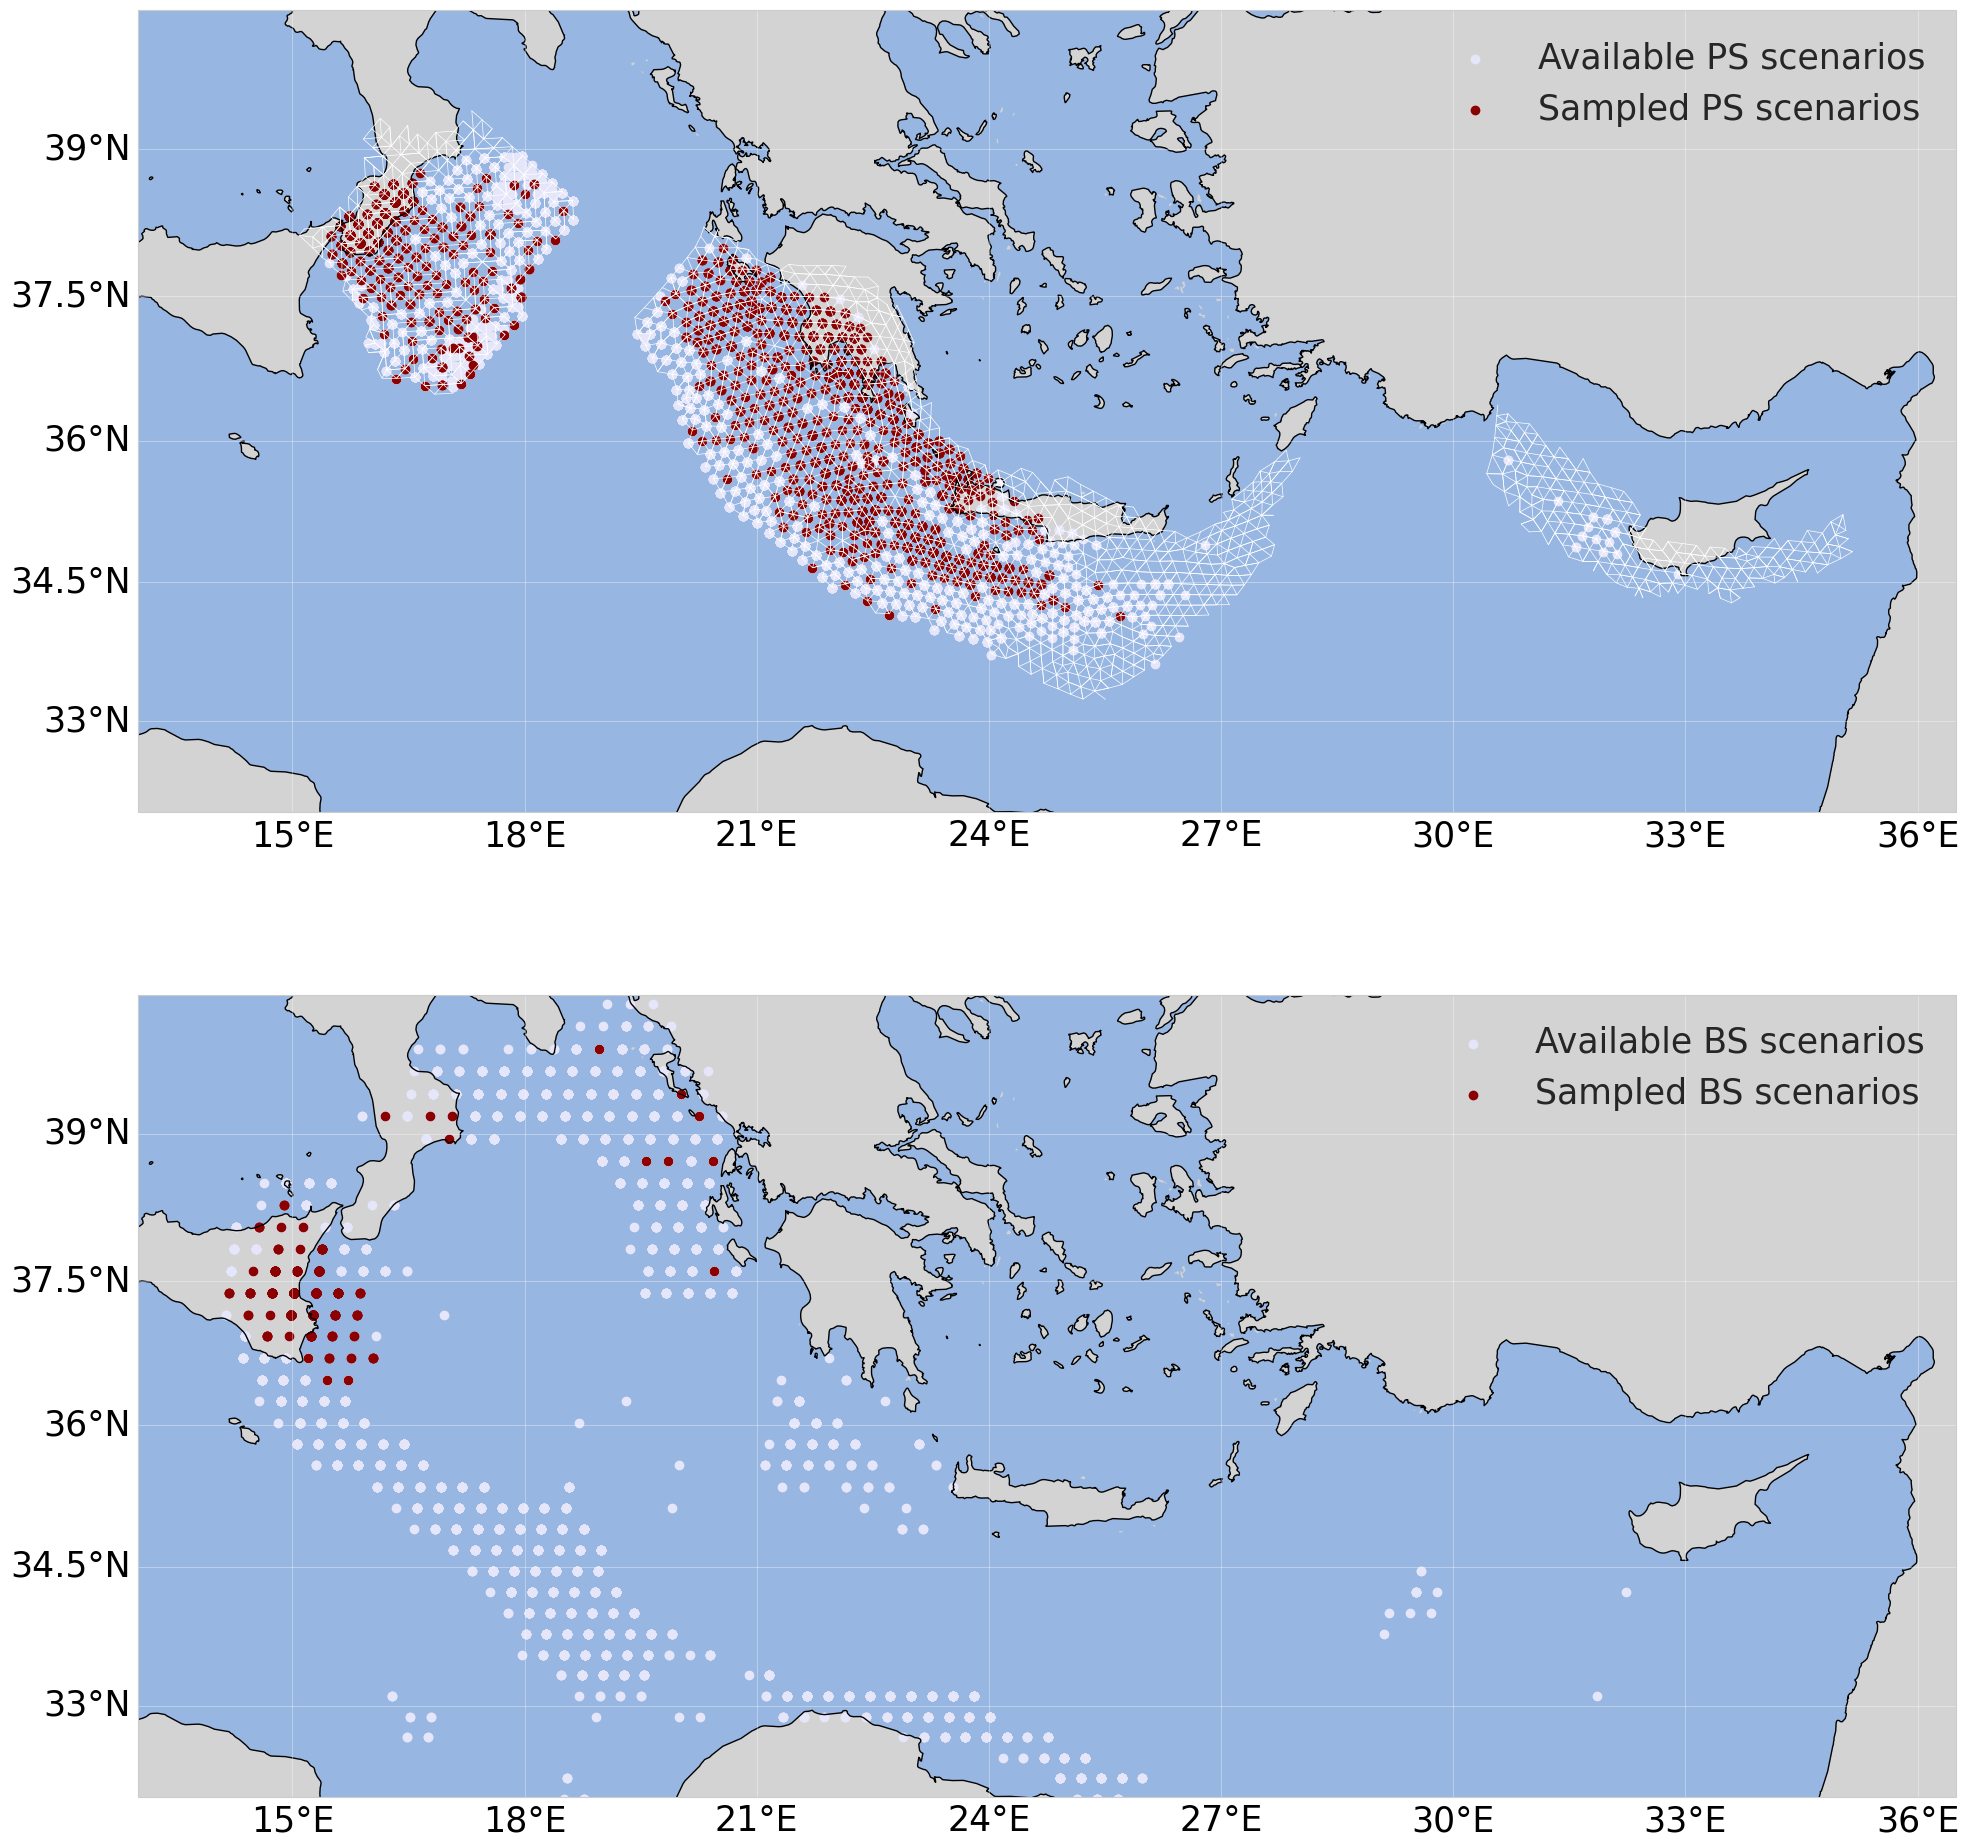

In [23]:
fig, axes = plt.subplots(2,1,
                       figsize    = (20,20),
                       subplot_kw = {'projection': cartopy.crs.Mercator()})
ax = axes[0]
fig.set_tight_layout(True)
proj = cartopy.crs.PlateCarree()

ax.set_extent([13, 36.5, 32, 40])
ax.add_feature(cartopy.feature.COASTLINE)
ax.add_feature(cartopy.feature.LAND, color  = 'lightgrey')
ax.add_feature(cartopy.feature.OCEAN)#, color = 'lightskyblue')
gl               = ax.gridlines(crs         = proj, 
                                draw_labels = True, 
                                linewidth   = 0.5,
                                color       = "#ffffff", 
                                alpha       = 0.5, 
                                linestyle   = '-')
ax.plot([mesh_med[:,0], mesh_med[:,2], mesh_med[:,4]],
        [mesh_med[:,1], mesh_med[:,3], mesh_med[:,5]],
        transform = proj,
        lw        = 0.5,
        c         = 'w')

ax.scatter(lon_ps, lat_ps,
           transform = proj,
           c      = 'lavender',
          label = 'Available PS scenarios')
ax.scatter(lon_ps_sis, lat_ps_sis,
           transform = proj,
           c      = 'darkred',
         label = 'Sampled PS scenarios')

gl.top_labels     = False
gl.right_labels   = False
gl.bottom_labels  = True
gl.left_labels    = True
gl.xformatter     = cartopy.mpl.gridliner.LONGITUDE_FORMATTER
gl.yformatter     = cartopy.mpl.gridliner.LATITUDE_FORMATTER
gl.xlabel_style   = {'size': 25, 'color': 'black'}
gl.ylabel_style   = {'size': 25, 'color': 'black'}

ax.legend(loc='upper right', frameon=False, fontsize=25)


ax = axes[1]
ax.set_extent([13, 36.5, 32, 40])
ax.add_feature(cartopy.feature.COASTLINE)
ax.add_feature(cartopy.feature.LAND, color  = 'lightgrey')
ax.add_feature(cartopy.feature.OCEAN)#, color = 'lightblue')
gl               = ax.gridlines(crs         = proj, 
                                draw_labels = True, 
                                linewidth   = 0.5,
                                color       = "#ffffff", 
                                alpha       = 0.5, 
                                linestyle   = '-')
ax.scatter(lon_bs, lat_bs,
           transform = proj,
           c      = 'lavender',
           label = 'Available BS scenarios')
ax.scatter(lon_bs_sis, lat_bs_sis,
           transform = proj,
           c      = 'darkred',
           label = 'Sampled BS scenarios'
          )

gl.top_labels     = False
gl.right_labels   = False
gl.bottom_labels  = True
gl.left_labels    = True
gl.xformatter     = cartopy.mpl.gridliner.LONGITUDE_FORMATTER
gl.yformatter     = cartopy.mpl.gridliner.LATITUDE_FORMATTER
gl.xlabel_style   = {'size': 25, 'color': 'black'}
gl.ylabel_style   = {'size': 25, 'color': 'black'}

ax.legend(loc='upper right', frameon=False, fontsize=25)

fig.tight_layout()
plt.show()